# The engine reference, the readiness document and the API contract: what each records and how a reader uses it

**Question:** How is the TypeScript engine of the browser held to the Python engine within a stated tolerance, what do the readiness document and the API contract record about the rest of the product, and how does a reader tell from them what can be trusted?

- Level: 2, the method in practice. Contracts: engine-reference, readiness and api.
- Prerequisites: `01-fourier-optics/02-reading-a-trap-array`, which reads the case contracts that these three sit beside.
- Reading time: about 30 minutes. The notebook runs in about 10 seconds.

## Objectives

DinHot computes the same holograms in two places: the Python engine of the pipeline and a TypeScript engine in the browser. A user trusts the second only if something ties it to the first, and trusts a number on the screen only if the product says what it was built from. Three contracts carry that: the engine reference, which stores the answers of the Python engine for the TypeScript tests to compare against, the readiness document, which says for every contract whether it is available, partial, stale or still served by a stand-in, and the API contract, which says what the service answers when something is missing. By the end you can:

- read an engine-reference document, decode its arrays and state the rule by which a port is accepted;
- find, by a sweep, the size of a difference at which that rule starts to fail, and say why a single-precision port would fail it;
- read the readiness document row by row, say what each state and provenance means, and list what is not available and why;
- read the API contract and say what a caller gets from each route when its document is absent;
- write a reference document for a function of your own and choose its tolerance from evidence.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import base64
import json
import sys
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.holo.core import forward
from pipeline.model.holo.core.geometry import Setup
from pipeline.stages import engine_reference as stage

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads three committed documents, each the output of a stage or a hand-kept contract, and one text file:

- `tests/fixtures/engine/*.json`: the engine reference, one document per function or method of the Python engine (46 files);
- `data/derived/readiness.json`: the readiness document, one row per contract;
- `docs/contracts/api.openapi.json`: the API contract, in OpenAPI form;
- `docs/contracts/catalog.md`: the catalog whose rows the readiness rules read.

Owner: this repository; all four are generated or kept by the product, with no third-party dataset. Licence class: the repository's own licence. The reference documents are seeded: their inputs are stored with their outputs, so a reader needs no other file to use them.

In [2]:
# the engine reference (46 documents), the readiness document and the API contract
reference = {
    p.stem: json.loads(p.read_text(encoding="utf-8"))
    for p in sorted((ROOT / "tests/fixtures/engine").glob("*.json"))
}
readiness = json.loads((ROOT / "data/derived/readiness.json").read_text(encoding="utf-8"))
openapi = json.loads((ROOT / "docs/contracts/api.openapi.json").read_text(encoding="utf-8"))
product_version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
cases_total = sum(len(d["cases"]) for d in reference.values())
print(
    len(reference), "reference documents,", cases_total, "cases | schema", {d["schema"] for d in reference.values()}
)
print(
    len(readiness["contracts"]),
    "readiness rows | product",
    readiness["product_version"],
    "| API routes",
    len(openapi["paths"]),
)

46 reference documents, 119 cases | schema {'dinhot.engine-ref/v1'}
11 readiness rows | product 0.02.002 | API routes 8


## Method

### Step 1: what a reference document records

A reference document holds one function or method of the Python engine. It states the name, the schema `dinhot.engine-ref/v1`, the version of the engine that wrote it, a tolerance, and a list of cases. Each case has `inputs` and `outputs`, and the inputs are seeded and stored, so that the TypeScript test reads both from the file and regenerates nothing. A number array is stored as `{shape, complex, data}` when it has at most 64 values and as `{shape, complex, b64}` above that, with the values as little-endian float64 and complex numbers interleaved as real and imaginary parts; integers and scalars are plain JSON. The tolerance is a pair, an absolute part and a relative part, that applies to every float quantity of the document unless a case carries its own. The cell lists what the 46 documents hold, how their arrays are encoded and how many demand exact equality.

In [3]:
# what the 46 documents hold: functions, cases, encodings and the tolerances
def count_arrays(node):
    inline = int(isinstance(node, dict) and "shape" in node and "data" in node)
    packed = int(isinstance(node, dict) and "shape" in node and "b64" in node)
    kids = node.values() if isinstance(node, dict) else node if isinstance(node, list) else ()
    for kid in kids:
        a, b = count_arrays(kid)
        inline, packed = inline + a, packed + b
    return inline, packed


encodings = np.array([count_arrays(d["cases"]) for d in reference.values()]).sum(axis=0)
exact = [name for name, d in reference.items() if d["tolerance"] == {"abs": 0.0, "rel": 0.0}]
tight = min(d["tolerance"]["rel"] for d in reference.values() if d["tolerance"]["rel"] > 0)
loose = max(d["tolerance"]["rel"] for d in reference.values())
print(len(exact), "documents hold exact integer streams only or no float tolerance (abs and rel zero):", exact)
print("arrays stored inline:", int(encodings[0]), "| arrays stored as b64:", int(encodings[1]))
print(
    "engine versions that wrote them:",
    sorted({d["engine_version"] for d in reference.values()}),
    "| product",
    product_version,
)
print(f"tightest relative tolerance {tight:.0e} | loosest {loose:.0e}")

2 documents hold exact integer streams only or no float tolerance (abs and rel zero): ['device.quantize', 'zernike.noll_to_nm']
arrays stored inline: 77 | arrays stored as b64: 152
engine versions that wrote them: ['0.02.000'] | product 0.02.002
tightest relative tolerance 1e-14 | loosest 1e-08


The figure puts each document at its absolute and relative tolerance on logarithmic axes; the documents with a tolerance of exactly zero are not drawn.

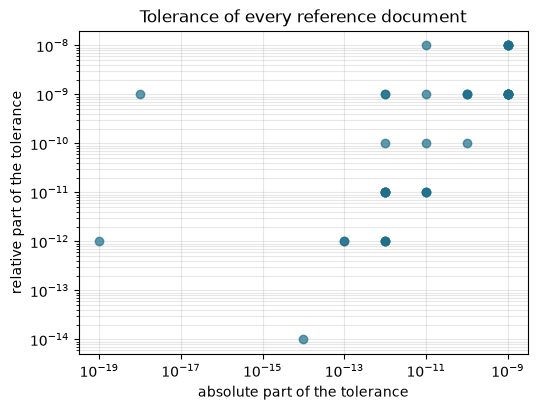

In [4]:
# the tolerance of every document: the absolute part against the relative part
points = np.array(
    [(d["tolerance"]["abs"], d["tolerance"]["rel"]) for d in reference.values() if d["tolerance"]["rel"] > 0]
)
fig, ax = plt.subplots(figsize=(5.8, 4.2))
ax.loglog(points[:, 0].clip(1e-19), points[:, 1], "o", color="#1f6f8b", alpha=0.7)
ax.set_xlabel("absolute part of the tolerance")
ax.set_ylabel("relative part of the tolerance")
ax.set_title("Tolerance of every reference document")
ax.grid(True, which="both", alpha=0.3)
plt.show()

The 46 documents hold 119 cases and 77 arrays inline and 152 packed as base64, and 2 of them ask for exact equality, the quantizer and the map of Noll indices, whose outputs are levels and integers. The tolerances range from a relative 1e-14 to 1e-08, and the figure shows that they are not one number: a document of plain arithmetic, such as a pixel envelope, is held to about $10^{-12}$, while the documents of whole methods that iterate, whose rounding accumulates through the loop, are held to about $10^{-8}$. The reason for each tolerance is written in the report that produced it, not in the document, which is why a reader should treat the figure as a record of what the port was found to need and not as a statement of what the mathematics allows. Points with an absolute part of zero are drawn at the floor of the axis. The versions in the printout are the engine versions that wrote the files: they say 0.02.000 while the product is 0.02.002, and the readiness rules do not mark this contract stale for that, since a reference is a test input and not a bake of the engine of the day.

### Step 2: the rule of acceptance, and the Python engine against its own reference

A port is accepted on a document when every float quantity of every case satisfies, for the reference value $r_i$ and the port's value $a_i$,

$$\lvert a_i - r_i \rvert \le \tau_{\mathrm{abs}} + \tau_{\mathrm{rel}}\,\lvert r_i \rvert,$$

with $\tau_{\mathrm{abs}}$ and $\tau_{\mathrm{rel}}$ the pair of the document, or of the case if it overrides it, and when every integer stream is identical. The absolute part keeps the rule meaningful where the reference is near zero and the relative part keeps it meaningful where it is large. The TypeScript tests apply this rule to the browser engine; the notebook cannot run the TypeScript, so it does the two things it can do on the Python side. It writes the rule as a function that decodes a document and returns the largest fraction of the tolerance that any value uses, and it regenerates the 42 documents that the stage produces without the long live-grid runs, through the stage's own `all_documents`, to see whether the committed files still describe the engine that is in the repository.

In [5]:
# the rule of the reference as two functions: decode a stored array, and the share of the tolerance a value uses
def decode(node):
    if isinstance(node, dict) and "shape" in node:
        raw = base64.b64decode(node["b64"]) if "b64" in node else None
        values = np.frombuffer(raw, dtype="<f8") if raw is not None else np.asarray(node["data"], dtype=float)
        if node["complex"]:
            values = values[0::2] + 1j * values[1::2]
        return values.reshape(node["shape"])
    return np.asarray(node)


def margin(port, ref, tol):
    """Largest share of the tolerance used by any value: at most 1 means the rule holds."""
    a, r = decode(port), decode(ref)
    return (
        float(np.max(np.abs(a - r) / (tol["abs"] + tol["rel"] * np.abs(r))))
        if tol["abs"] + tol["rel"] > 0
        else float(np.any(a != r))
    )

The next cell regenerates the 42 documents with the engine of the repository and compares them with the committed ones, and then calls the engine by hand on one stored case.

In [6]:
# the Python engine regenerated against the committed documents
fresh = {}
for key, produced in stage.all_documents(live=False).items():
    fresh[key] = json.loads(stage.dump(produced))
used = {}
for name, doc in fresh.items():
    shares = []
    for new_case, old_case in zip(doc["cases"], reference[name]["cases"]):
        for key, old in old_case["outputs"].items():
            if isinstance(old, dict) and "shape" in old:
                shares.append(margin(new_case["outputs"][key], old, reference[name]["tolerance"]))
    used[name] = max(shares, default=0.0)
same = sum(1 for name, doc in fresh.items() if doc["cases"] == reference[name]["cases"])
print(same, "of the", len(fresh), "documents regenerate to identical cases:", same == len(fresh))
print(f"largest margin used (1 is the edge of the tolerance): {max(used.values()):.3g}")
case = reference["forward.fft_focal_field"]["cases"][0]
one_field = forward.fft_focal_field(decode(case["inputs"]["phi"]), Setup(**case["inputs"]["setup"]))
one_margin = margin(one_field, case["outputs"]["e"], reference["forward.fft_focal_field"]["tolerance"])
print(f"one case by hand, the engine called on its stored inputs: share of the tolerance used {one_margin:.3g}")

42 of the 42 documents regenerate to identical cases: True
largest margin used (1 is the edge of the tolerance): 0
one case by hand, the engine called on its stored inputs: share of the tolerance used 0


42 of the 42 documents regenerate to cases identical to the committed ones, and the largest share of the tolerance that any value uses is 0. So the committed reference describes the Python engine of the repository exactly, which is what the contract test of the stage asserts by regenerating and comparing, and the TypeScript port is the only thing between the two that has room to differ. Called by hand on the stored inputs of the first focal-field case, the engine uses 0 of the tolerance. This is a statement about today's repository and one stage run; it says nothing about the TypeScript, and a reference that had silently drifted from the engine would turn a failing port into a passing one, which is why the regeneration is part of the product's tests and not an option.

### Sensitivity of the acceptance rule to the size of a difference

The rule has a size built into it, the tolerance, and the useful question is what that size means in terms of ports that exist. The cell takes the float outputs of three documents, the crosstalk of the device model, the focal field of the forward model and the weighted loop M06, adds to every value a relative difference $\delta$ from $10^{-16}$ to $10^{-4}$, and measures the share of values that stay within the tolerance. It adds a case that is not a constructed one, the same values cast to single precision, the arithmetic of a port that did not use doubles; for a float32 number the rounding error is bounded by the unit roundoff

$$u = 2^{-24} \approx 6 \times 10^{-8}$$

in relative terms (Higham, 2002, chapter 2; IEEE 754-2019), so a port that stores intermediate values in single precision differs from the reference by about $u\,\lvert r_i \rvert$ at every value, which is above every tolerance in the figure of Step 1.

In [7]:
# a difference of relative size delta added to every value of three documents, and the same values in single
# precision
deltas = 10.0 ** np.arange(-16, -3.9, 0.5)
sweep = {}
for name in ("device.crosstalk", "forward.fft_focal_field", "methods.M06"):
    tol = reference[name]["tolerance"]
    refs = np.concatenate(
        [
            np.ravel(decode(v)).view(float) if np.iscomplexobj(decode(v)) else np.ravel(decode(v))
            for c in reference[name]["cases"]
            for v in c["outputs"].values()
            if isinstance(v, dict) and "shape" in v
        ]
    )
    band = tol["abs"] + tol["rel"] * np.abs(refs)
    passing = [float(np.mean(np.abs(d * refs) <= band)) for d in deltas]
    single = float(np.mean(np.abs(refs.astype(np.float32).astype(np.float64) - refs) <= band))
    sweep[name] = (passing, single, tol["rel"])
    print(f"{name:26s} relative tolerance {tol['rel']:.0e} | single precision: share accepted {single:.3f}")

device.crosstalk           relative tolerance 1e-11 | single precision: share accepted 0.001
forward.fft_focal_field    relative tolerance 1e-11 | single precision: share accepted 0.001
methods.M06                relative tolerance 1e-09 | single precision: share accepted 0.066


The curves plot the share of accepted values against the relative difference; the markers at the right are the single-precision cast of each document.

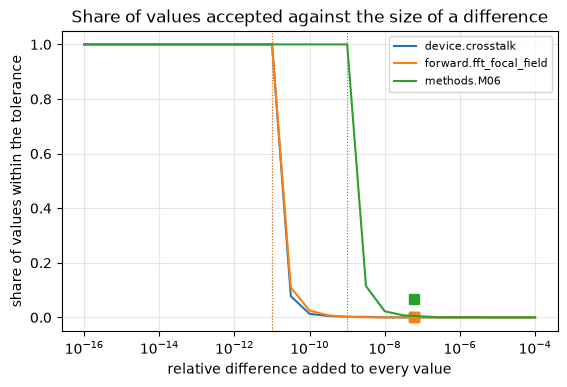

In [8]:
# the share of values accepted against the relative difference, and the single-precision cast of each document
fig, ax = plt.subplots(figsize=(6.4, 3.9))
for name, (passing, single, rel) in sweep.items():
    line = ax.semilogx(deltas, passing, "-", label=name)[0]
    ax.plot([6e-8], [single], "s", color=line.get_color(), markersize=7)
    ax.axvline(rel, color=line.get_color(), linestyle=":", linewidth=0.8)
ax.set_xlabel("relative difference added to every value")
ax.set_ylabel("share of values within the tolerance")
ax.set_title("Share of values accepted against the size of a difference")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.show()

Each curve falls from 1 to 0 within about a decade, and the fall happens at the relative tolerance of its document, marked by the dotted line of the same colour: 1e-11 for the crosstalk, 1e-11 for the focal field and 1e-09 for M06. Below that line a difference is invisible to the rule and above it every value is refused, so the tolerance is the resolution of the check and not a margin of safety on top of it. The squares are the single-precision cast, drawn at $u$: they sit at 0.001, 0.001 and 0.066 of the values accepted, so a port in single precision would fail all three, which is the argument for keeping the browser engine in doubles. The figure uses a difference of one size for every value, an idealised port; a real port differs by an amount that depends on the value, which the single-precision cast imitates better, and the real arbiter is the TypeScript test itself.

The sweep perturbed the outputs. A port also differs in what it is given, so the next cell perturbs the input phases of the engine itself by a relative amount $\varepsilon$ and measures how much of that reaches the focal field, relative to its peak. If the transform did not amplify differences, the output would change by about $\varepsilon$ times the size of the phases, and a tolerance of $10^{-11}$ would then require the inputs of a port to match to about $10^{-11}$, which is the reason the reference stores the inputs with the outputs.

In [9]:
# the engine on phases off by a relative amount eps: how much of the input difference reaches the focal field
probe_setup, probe_phase = stage.S(16, 2), stage.phases(5, 16)
probe_ref = forward.fft_focal_field(probe_phase, probe_setup)
reach = {}
for eps in (1e-14, 1e-12, 1e-10, 1e-8, 1e-6):
    moved = forward.fft_focal_field(probe_phase * (1 + eps), probe_setup)
    reach[eps] = float(np.max(np.abs(moved - probe_ref)) / np.max(np.abs(probe_ref)))
    print(f"input phases off by {eps:.0e}: largest output difference relative to the peak {reach[eps]:.2e}")

input phases off by 1e-14: largest output difference relative to the peak 7.11e-14
input phases off by 1e-12: largest output difference relative to the peak 7.11e-12
input phases off by 1e-10: largest output difference relative to the peak 7.11e-10
input phases off by 1e-08: largest output difference relative to the peak 7.11e-08
input phases off by 1e-06: largest output difference relative to the peak 7.11e-06


The output difference is 7.1e-12 for an input difference of $10^{-12}$ and 7.1e-08 for $10^{-8}$, which is 7.1 times the input difference at the larger one: the transform neither hides nor amplifies a difference by much, so what a port gets wrong at its input is what the reference sees at its output. Under the tolerance of $10^{-11}$ of the focal field a port must therefore read its inputs from the file and not recompute them with a different random generator, and must not round them. The test uses one setup and one phase pattern, and a function that amplifies differences, such as an iterated method, needs a looser tolerance, which is what the tolerances of the method documents show.

### Step 3: the readiness document

The readiness document is one row per contract of the catalog, written by the stage `readiness` from the catalog and the state of the repository. Each row has the contract `id`, its `version`, the catalog `status` (`real` or `active`), a `provenance` (`real`, `baseline` or null) and a `state`, one of `available`, `partial`, `stale`, `missing`, `training` or `provider`, with a `reason` in English and Spanish and, for `partial`, the list `missing` of what is absent. The state of a row is the first rule of the catalog's table that matches, applied in order: a row served by a stand-in is `provider`; a document that is absent is `missing`; a document with absent parts is `partial`; a document baked by another version of the engine is `stale`; a model slot with no released graph is `training` with the provenance `baseline`; anything else is `available`. The cell counts the states and prints every row that is not available with its reason.

In [10]:
# the rows of the readiness document by state and provenance, and the ones that are not available
rows = readiness["contracts"]
by_state = Counter(r["state"] for r in rows)
print("rows by state:", dict(by_state))
for row in rows:
    if row["state"] != "available":
        print(
            f"{row['id']:16s} {row['state']:9s} provenance {row['provenance']} | "
            f"{(row['reason'] or {}).get('en')} | missing {len(row['missing'])}: {row['missing'][:5]}"
        )

rows by state: {'partial': 2, 'available': 7, 'training': 1, 'missing': 1}
params-record    partial   provenance real | 1 of 14 records rejected by contract 1. | missing 1: ['C11_outside_field']
benchmark-results partial   provenance real | 61 of 168 benchmark cells were not run. | missing 61: ['B1/G5', 'B1/G7', 'B2/G7', 'B3/G7', 'B4/G5']
warmstart-model  training  provenance baseline | No released model; the slot's baseline answers (GS for cgh-net, random trap phases for warmstart-model). | missing 0: []
api              missing   provenance None | The API lane is dormant; the site reads the committed documents. | missing 0: []


The bars count the rows by state.

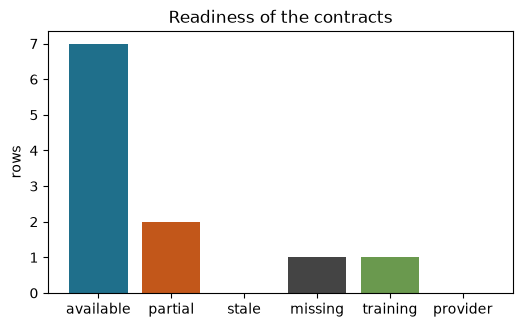

In [11]:
# the states of the 11 rows, counted
states = ["available", "partial", "stale", "missing", "training", "provider"]
fig, ax = plt.subplots(figsize=(6.0, 3.4))
ax.bar(
    states,
    [by_state.get(s, 0) for s in states],
    color=["#1f6f8b", "#c2571a", "#999999", "#444444", "#6a994e", "#bb8fce"],
)
ax.set_ylabel("rows")
ax.set_title("Readiness of the contracts")
plt.show()

Of the 11 rows, 7 are available, 2 are partial, 1 is in training and 1 is missing. The partial rows are the ones that need reading: the parameter records have one record rejected by contract 1, which is the case C11 outside the field of view that the product refuses by design, and the benchmark has cells that were not run, whose count the printout gives with the first five. A partial row is not a defect to be fixed in every case; it is a statement of exactly what a view will say is not available yet. The row in training is the warm-start model, served by its baseline, the random trap phases, and the notebooks of the learned topic showed the refused candidate behind it. The row missing is the API: the static document says the service lane is dormant, while the running service answers `/api/readiness` with the service as available. The figure does not say how much of the product each state covers, since a row is one contract and not a share of the functions; it counts rows only.

### Step 4: the API contract

The API contract is an OpenAPI document: for each route, the verbs it answers and, for each verb, the status codes that it documents with the schema of the body. The rule of the product for a document that the service cannot find is not an empty body: it is the status 503 with a body that carries the state `missing` and the reason, and a 404 for an unknown case or artifact. The cell lists the routes with their status codes and reads the shape of the 503 body.

In [12]:
# each route of the API contract with the status codes it documents
routes = {
    path: sorted({code for verb in item.values() if isinstance(verb, dict) for code in verb.get("responses", {})})
    for path, item in openapi["paths"].items()
}
for path, codes in routes.items():
    print(f"{path:34s} {codes}")
body = openapi["components"]["schemas"]["UnavailableBody"]["properties"]["detail"]
print(
    len(routes),
    "routes;",
    sum("503" in c for c in routes.values()),
    "document a 503 body with the fields",
    body["required"],
)

/health                            ['200']
/healthz                           ['200']
/api/cases                         ['200', '503']
/api/cases/{case_id}/manifest      ['200', '404', '503']
/api/artifacts/{rel_path}          ['200', '404', '503']
/api/benchmark                     ['200', '503']
/api/models/metrics                ['200', '503']
/api/readiness                     ['200', '503']
8 routes; 6 document a 503 body with the fields ['state', 'reason']


The grid marks, for every route, the status codes that the contract documents.

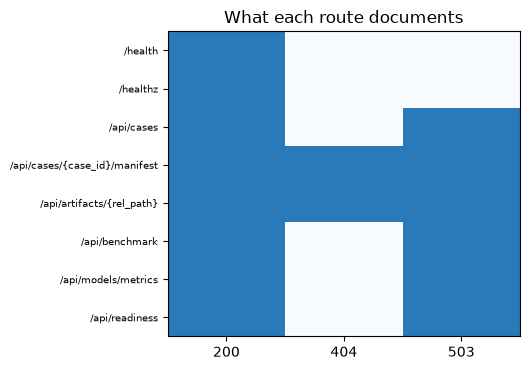

In [13]:
# the documented status codes of every route, as a table
codes = sorted({c for v in routes.values() for c in v})
grid = np.array([[1.0 if c in routes[p] else 0.0 for c in codes] for p in routes])
fig, ax = plt.subplots(figsize=(5.4, 3.8))
ax.imshow(grid, cmap="Blues", vmin=0, vmax=1.4, aspect="auto")
ax.set_xticks(range(len(codes)), codes)
ax.set_yticks(range(len(routes)), list(routes), fontsize=7)
ax.set_title("What each route documents")
plt.tight_layout()
plt.show()

The contract documents 8 routes, and 6 of them can answer a 503: the routes that serve a document of the bake, the list of cases, the benchmark, the model metrics and the readiness, answer with an unavailable body whose detail has 2 fields, the state and the reason, when the document is absent, and the health routes answer only 200. A caller therefore never has to treat an empty body as a result: a 200 carries the document, a 503 carries the state and the reason, and a 404 means the case or the artifact does not exist. The grid shows what is documented and not what is implemented, which the contract test of the API checks against the running responses. The routes that take a path parameter, a case or an artifact, are the ones documented with a 404.

### Use it on your own data

To tie a function of your own to a reference you write a document of the same shape and choose its tolerance. The product's stage gives the pieces: `arr` encodes an array as the contract says, `document` assembles the document from a function name, the two tolerances and a list of cases, and `dump` writes it with sorted keys and no clock, so that two runs write the same bytes. The cases hold the inputs, which must be seeded or constant, and the outputs of the Python function; a port in another language then reads the file and compares by the rule of Step 2. The tolerance is the only judgement in the document, and the sweep above says how to take it from evidence: find the largest difference between the port and the reference, and set the tolerance an order of magnitude above, never below.

The cell builds a reference for the focal field of a random 16 x 16 phase, encodes it, and decodes it again to check that the encoding loses nothing.

In [14]:
# your own function: the focal field of a random 16 x 16 phase, from the engine
own_setup = stage.S(16, 2)
own_phase = stage.phases(7, 16)
own_field = forward.fft_focal_field(own_phase, own_setup)
print("field", own_field.shape, own_field.dtype, f"| largest magnitude {np.abs(own_field).max():.3f}")

field (32, 32) complex128 | largest magnitude 1.342


The next cell encodes two cases as the stage does and reads the first back.

In [15]:
# your own reference document: the case encoded with the encoder of the stage, written and read back
second_phase = stage.phases(8, 16)
second_field = forward.fft_focal_field(second_phase, own_setup)
own_doc = stage.document(
    "my.fft_focal_field",
    1e-11,
    1e-10,
    [
        {
            "inputs": {"phi": stage.arr(phi), "setup": stage.setup_doc(own_setup)},
            "outputs": {"field": stage.arr(out)},
        }
        for phi, out in ((own_phase, own_field), (second_phase, second_field))
    ],
)
text = stage.dump(own_doc)
back = decode(json.loads(text)["cases"][0]["outputs"]["field"])
print(
    f"{len(text)} bytes; arrays above 64 values are stored as b64:",
    "b64" in json.loads(text)["cases"][0]["outputs"]["field"],
)
print("largest difference after the round trip through the decoder:", float(np.max(np.abs(back - own_field))))

49830 bytes; arrays above 64 values are stored as b64: True
largest difference after the round trip through the decoder: 0.0


The next cell builds the single-precision port of the same function and finds the tolerance that accepts it.

In [16]:
# a single-precision port of the same function: phases rounded to float32 before the engine runs
port = forward.fft_focal_field(own_phase.astype(np.float32).astype(np.float64), own_setup)
gap = np.abs(port - own_field)
size = np.abs(own_field)
worst = float(np.max(gap / size))
needed = 10 * worst
print(f"largest relative difference of the single-precision port: {worst:.2e}")
print(
    f"relative tolerance that accepts it with a margin of ten: {needed:.1e} | tolerance written in the "
    f"document: 1e-10"
)

largest relative difference of the single-precision port: 1.22e-05
relative tolerance that accepts it with a margin of ten: 1.2e-04 | tolerance written in the document: 1e-10


The scatter plots the difference of the single-precision port against the magnitude of each reference value, with the band that the tolerance of the document accepts.

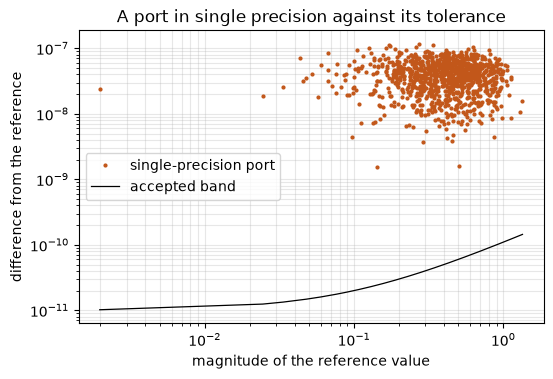

In [17]:
# the difference of the single-precision port against the magnitude of the reference, with the accepted band
magnitude = np.sort(size.ravel())
fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.loglog(size.ravel(), gap.ravel() + 1e-30, ".", color="#c2571a", markersize=4, label="single-precision port")
ax.loglog(magnitude, 1e-11 + 1e-10 * magnitude, "k-", linewidth=0.9, label="accepted band")
ax.set_xlabel("magnitude of the reference value")
ax.set_ylabel("difference from the reference")
ax.set_title("A port in single precision against its tolerance")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

The encoding of the field takes 49830 bytes and comes back with a largest difference of 0.0e+00, and the port that rounds its input phases to single precision differs from the reference by at most 1.2e-05 of the value at any point, so a document written with a relative tolerance of 1e-10 would refuse it, as the points above the band in the figure would show wherever they cross it, while the tolerance that accepts it with a margin of ten is 1.2e-04. That is the decision the document asks of its author: write the tolerance of the port that you want to accept, and a port that does not meet it fails the test with the number that it missed. The figure does not tell whether a single-precision port is good enough for the application, only whether it would pass a reference written in doubles; whether a difference of this size matters for the holograms is a question for the method notebooks, and the answer depends on how many iterations carry the error forward.

## Results

**Answer:** The TypeScript engine is held to the Python engine by a stored reference: 46 documents with 119 seeded cases, each carrying a tolerance pair that ranges from a relative 1e-14 to 1e-08, and a port is accepted when every value satisfies the absolute plus relative rule and every integer stream is identical. The Python engine reproduces its own reference exactly, 42 of 42 documents regenerating identically, and the rule is sharp: the share of accepted values falls from 1 to 0 at the relative tolerance of the document, and a single-precision port would be refused on all three documents tried. The readiness document gives every contract a state, with 7 of 11 available and 2 partial, and the API contract answers a missing document with a 503 body that carries the state and the reason, on 6 of 8 routes. What the notebook could not do is run the TypeScript port against the reference, which is the work of the frontend tests.

## Summary

- A reference document stores seeded inputs with the Python engine's outputs and a tolerance pair; a port is accepted when each value satisfies the absolute plus relative rule and each integer stream is identical.
- The committed reference regenerates exactly from the Python engine, and the tolerance is the resolution of the check: a difference below it is invisible and above it every value is refused.
- A port in single precision would fail the tolerances of the documents tried, so the browser engine stays in doubles.
- The readiness document states for each contract available, partial, stale, missing, training or provider, with the reason and the list of what is absent, and the API contract answers a missing document with a 503 body and never an empty one.
- A reference for a function of your own needs seeded inputs, the stage's encoder and a tolerance taken from the largest difference of a real port, an order of magnitude above it.

## References

- Higham (2002). Accuracy and Stability of Numerical Algorithms, second edition. SIAM. https://doi.org/10.1137/1.9780898718027
- IEEE (2019). IEEE standard for floating-point arithmetic, IEEE Std 754-2019. https://doi.org/10.1109/IEEESTD.2019.8766229
- OpenAPI Initiative (2021). OpenAPI Specification, version 3.1.0. https://spec.openapis.org/oas/v3.1.0
- Goldberg (1991). What every computer scientist should know about floating-point arithmetic. ACM Computing Surveys 23, 5. https://doi.org/10.1145/103162.103163
- matplotlib 3.11.2, the plotting library of the notebooks. https://pypi.org/pypi/matplotlib/json